In [1]:
import sys
from pathlib import Path
import numpy as np

In [2]:
current = Path.cwd().resolve()
ROOT = None

In [3]:
for folder in (current,) + tuple(current.parents):
    if (folder / "data" / "train" / "X.npy").is_file():
        ROOT = folder
        break

if ROOT is None:
    raise FileNotFoundError(
        "No se encontro data/train/X.npy subiendo desde {}.".format(current)
    )

if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from src.pipeline import iq_a_complejo


In [4]:
X_val = np.load(ROOT / "data" / "val" / "X.npy", mmap_mode="r")
obs = X_val[0]
complejo = iq_a_complejo(obs)

assert complejo.shape == (1024,)
assert np.array_equal(complejo.real, obs[0])
assert np.array_equal(complejo.imag, obs[1])

try:
    iq_a_complejo(obs[:, :512])
except ValueError as error:
    print(error)

print(complejo.dtype)


Se esperaba forma (2, 1024), llegó (2, 512).
complex64


In [5]:
import csv
import joblib

from src.features import extract_features

MODEL_PATH = ROOT / "models" / "random_forest.joblib"
rf = joblib.load(str(MODEL_PATH))
print("Clases:", rf.classes_)

with (ROOT / "data" / "val" / "meta.csv").open(
    "r", newline="", encoding="utf-8"
) as file:
    metadata = list(csv.DictReader(file))

indice = 1000
meta = metadata[indice]
complejo = iq_a_complejo(X_val[indice])
features = extract_features(complejo)

assert features.shape == (6,)

# El bosque se entrenó sin C21 (columna 1). Queda una fila (1, 5).
fila = np.delete(features, 1).reshape(1, -1)
assert fila.shape == (1, rf.n_features_in_)

proba = rf.predict_proba(fila)
bpsk = list(rf.classes_).index("BPSK")

print(
    "Fila {}: {} a {:.2f} dB instantaneos.".format(
        indice,
        meta["mod"],
        float(meta["snr_inst_db"]),
    )
)
print("|C20| = {:.4f}".format(float(features[0])))
for nombre, valor in zip(rf.classes_, proba[0]):
    print("{}: {:.4f}".format(nombre, valor))

assert meta["mod"] == "BPSK"
assert abs(float(meta["snr_inst_db"]) - 8.0) < 1.0
assert proba[0, bpsk] > 0.9


Clases: ['16APSK' '16QAM' '64QAM' '8PSK' 'BPSK' 'QPSK' 'ruido']
Fila 1000: BPSK a 7.93 dB instantaneos.
|C20| = 0.3781
16APSK: 0.0010
16QAM: 0.0097
64QAM: 0.0000
8PSK: 0.0000
BPSK: 0.9828
QPSK: 0.0065
ruido: 0.0000


In [6]:
import torch

from src.models import ModulationCNN
from src.pre_procesamiento import CLASSES, normalize_iq_batch

cnn = ModulationCNN(num_classes=len(CLASSES))
estado = torch.load(
    str(ROOT / "models" / "cnn.pt"),
    map_location="cpu",
)
cnn.load_state_dict(estado)
cnn.eval()

lote = normalize_iq_batch(X_val[indice:indice + 1])
assert lote.shape == (1, 2, 1024)

tensor = torch.from_numpy(lote)

with torch.no_grad():
    logits = cnn(tensor)
    proba_cnn = torch.softmax(logits, dim=1)[0]

print("Clases CNN:", CLASSES)
print("Azar, 1/7: {:.4f}".format(1.0 / len(CLASSES)))
for nombre, valor in zip(CLASSES, proba_cnn.tolist()):
    print("{}: {:.4f}".format(nombre, valor))

assert CLASSES[0] == "BPSK"
assert int(torch.argmax(proba_cnn)) == 0


Clases CNN: ('BPSK', 'QPSK', '8PSK', '16QAM', '64QAM', '16APSK', 'ruido')
Azar, 1/7: 0.1429
BPSK: 1.0000
QPSK: 0.0000
8PSK: 0.0000
16QAM: 0.0000
64QAM: 0.0000
16APSK: 0.0000
ruido: 0.0000


In [7]:
import importlib
import src.pipeline as pipeline

importlib.reload(pipeline)
analizar = pipeline.analizar
medir_snr = pipeline.medir_snr

resultado = analizar(X_val[indice], cnn)
ruido = analizar(X_val[9600], cnn)

print(resultado)
print(ruido)

assert resultado.hay_senal
assert resultado.clase == "BPSK"
assert resultado.confianza > 0.9
assert resultado.snr_db is not None
assert abs(resultado.snr_db - float(meta["snr_inst_db"])) < 2.0
assert ruido.hay_senal is False
assert ruido.clase == "ruido"
assert ruido.confianza is None
assert ruido.snr_db is None

errores = []
for i, row in enumerate(metadata):
    referencia = float(row["snr_inst_db"])
    if not np.isfinite(referencia):
        continue
    estimado = medir_snr(iq_a_complejo(X_val[i]))
    if estimado is None:
        continue
    errores.append(abs(estimado - referencia))

errores = np.asarray(errores, dtype=np.float64)
print(
    "Error medio de SNR: {:.3f} dB sobre {} filas.".format(
        float(np.mean(errores)),
        len(errores),
    )
)


Resultado(hay_senal=True, snr_db=7.713840874384496, clase='BPSK', confianza=0.9999983310699463)
Resultado(hay_senal=False, snr_db=None, clase='ruido', confianza=None)
Error medio de SNR: 1.052 dB sobre 9005 filas.


In [8]:
senal = np.array(
    [i for i, row in enumerate(metadata) if row["mod"] != "ruido"],
    dtype=np.int64,
)
assert len(senal) == 9600

confianza = np.empty(len(senal), dtype=np.float64)
clase = np.empty(len(senal), dtype=object)
snr_db = np.empty(len(senal), dtype=np.float64)
mod_verdadera = np.empty(len(senal),dtype=object) #resp correcta

clase_cnn = np.empty(len(senal),dtype=object) #
nombres = np.asarray(CLASSES)
tam_lote = 128 

cnn.eval()


with torch.no_grad():
    for inicio in range(0, len(senal),tam_lote):
        tramo = slice (inicio,inicio+tam_lote)
        lote = normalize_iq_batch(X_val[senal[tramo]])
        
        logits = cnn(torch.from_numpy(lote))
        indices_clase = logits.argmax(dim=1).tolist()
        clase_cnn[tramo]= nombres[indices_clase]

for k, i in enumerate(senal):
    resultado = analizar(X_val[i], cnn)
    
    if resultado.confianza is None:
        confianza[k] = np.nan
    else:
        confianza[k] = resultado.confianza
        
    clase[k] = resultado.clase
    snr_db[k] = float(metadata[i]["snr_db"])
    mod_verdadera[k]=metadata[i]["mod"] #misma señal, fila original 1

assert confianza.shape == (9600,)
print("Mod_verdaderas:", np.unique(mod_verdadera))
assert clase.shape == (9600,)
assert snr_db.shape == (9600,)
assert np.all(np.isfinite(snr_db))

print(
    "Senales: {}. Confianza ausente (detector en silencio): {}.".format(
        len(senal),
        int(np.count_nonzero(np.isnan(confianza))),
    )
)
print("snr_db del CSV:", np.unique(snr_db))


Mod_verdaderas: ['16APSK' '16QAM' '64QAM' '8PSK' 'BPSK' 'QPSK']
Senales: 9600. Confianza ausente (detector en silencio): 2318.
snr_db del CSV: [-10.  -8.  -6.  -4.  -2.   0.   2.   4.   6.   8.  10.  12.  14.  16.
  18.  20.]


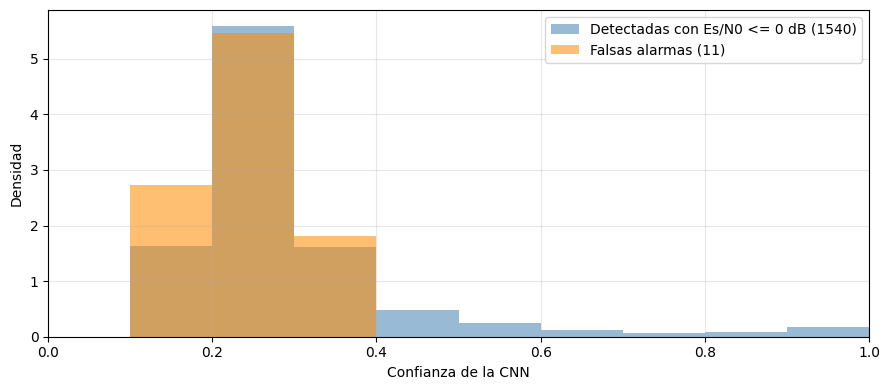

Bajas: 0.153 a 1.000. Falsas alarmas: 0.166 a 0.386.


In [9]:
import matplotlib.pyplot as plt

detectadas = np.isfinite(confianza)
assert int(np.count_nonzero(detectadas)) == 7282

bajas = confianza[detectadas & (snr_db <= 0.0)]

falsas = []
for i, row in enumerate(metadata):
    if row["mod"] != "ruido":
        continue
    resultado = analizar(X_val[i], cnn)
    if resultado.confianza is None:
        continue
    falsas.append(resultado.confianza)

falsas = np.asarray(falsas, dtype=np.float64)
assert len(falsas) == 11

bins = np.linspace(0.0, 1.0, 11)
fig, ax = plt.subplots(figsize=(9, 4))
ax.hist(
    bajas,
    bins=bins,
    density=True,
    alpha=0.55,
    color="steelblue",
    label="Detectadas con Es/N0 <= 0 dB ({})".format(len(bajas)),
)
ax.hist(
    falsas,
    bins=bins,
    density=True,
    alpha=0.55,
    color="darkorange",
    label="Falsas alarmas ({})".format(len(falsas)),
)
ax.set_xlabel("Confianza de la CNN")
ax.set_ylabel("Densidad")
ax.set_xlim(0.0, 1.0)
ax.grid(alpha=0.3)
ax.legend()
plt.tight_layout()
plt.show()

print(
    "Bajas: {:.3f} a {:.3f}. Falsas alarmas: {:.3f} a {:.3f}.".format(
        float(bajas.min()),
        float(bajas.max()),
        float(falsas.min()),
        float(falsas.max()),
    )
)


In [10]:
aciertos_cnn = clase_cnn == mod_verdadera

print(f"Aciertos de la CNN {aciertos_cnn.sum()} de {len(aciertos_cnn)}")
print(f"Exactitud de la CNN:{aciertos_cnn.mean():.2%}")

Aciertos de la CNN 3929 de 9600
Exactitud de la CNN:40.93%


In [11]:
aciertos_sistema = clase == mod_verdadera
silencios_detector = np.isnan(confianza)

print(f"CNN sola: {aciertos_cnn.mean():.2%}")
print(f"Detector + CNN: {aciertos_sistema.mean():.2%}")
print(f"Señales que el detector dejó pasar: {(~silencios_detector).sum()} de {len(clase)}")
print(f"Señales en silencio que la CNN sola acertaba: {(silencios_detector & aciertos_cnn).sum()}")

CNN sola: 40.93%
Detector + CNN: 39.76%
Señales que el detector dejó pasar: 7282 de 9600
Señales en silencio que la CNN sola acertaba: 112


In [12]:
niveles = np.unique(snr_db)

acierto_cnn = clase_cnn==mod_verdadera
aciertos_sistema = clase==mod_verdadera
acierto_umbral = aciertos_sistema & (confianza >= 0.4)

curva_cnn = []
curva_sistema = []
curva_umbral = []

for nivel in niveles:
    grupo = snr_db == nivel 
    
    curva_cnn.append(100*acierto_cnn[grupo].mean())
    curva_sistema.append(100* aciertos_sistema[grupo].mean())
    curva_umbral.append(100* acierto_umbral[grupo].mean())
    

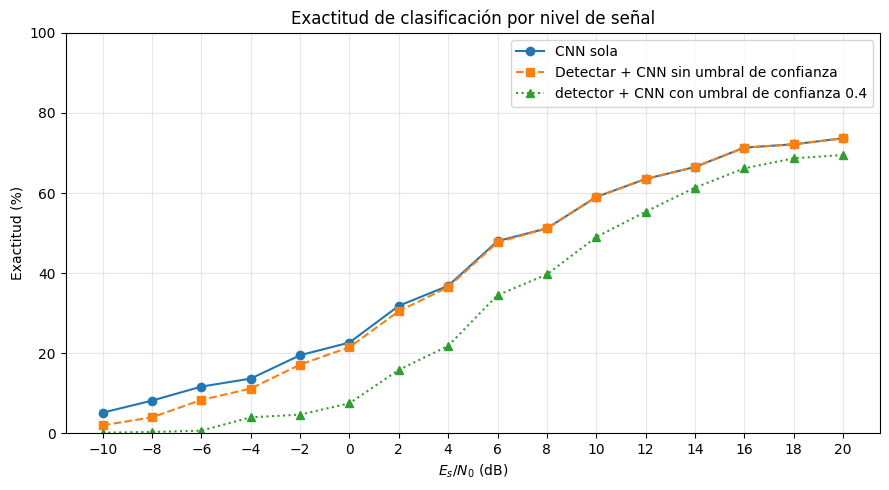

Figura guardada en /home/lcmj2803/coms_proyecto2/figs/integracion/exactitud_vs_esn0.png


In [13]:
carpeta = ROOT/"figs"/"integracion"
carpeta.mkdir(parents=True, exist_ok=True)

fig,ax = plt.subplots(figsize=(9,5))

ax.plot(niveles, curva_cnn, "o-", label="CNN sola")
ax.plot(niveles, curva_sistema, "s--",label="Detectar + CNN sin umbral de confianza")
ax.plot(niveles, curva_umbral, "^:", label="detector + CNN con umbral de confianza 0.4")

ax.set_xlabel(r"$E_s/N_0$ (dB)")
ax.set_ylabel("Exactitud (%)")
ax.set_title("Exactitud de clasificación por nivel de señal")
ax.set_xticks(niveles)
ax.set_ylim(0, 100)
ax.grid(alpha=0.3)
ax.legend()
fig.tight_layout()

ruta = carpeta / "exactitud_vs_esn0.png"
fig.savefig(ruta, dpi=200)
plt.show()

print(f"Figura guardada en {ruta.resolve()}")

In [14]:
importlib.reload(pipeline)
analizar = pipeline.analizar

# 1. Sin umbral no cambia nada; con 0.4, BPSK de la fila 1000 sigue igual.
sin_umbral = analizar(X_val[indice], cnn)
con_umbral = analizar(X_val[indice], cnn, umbral=0.4)
print(sin_umbral)
assert sin_umbral == con_umbral
assert con_umbral.clase == "BPSK"

# 2. Ruidos: cuántos salen con una modulación, con y sin umbral.
ruidos = [i for i, row in enumerate(metadata) if row["mod"] == "ruido"]
assert len(ruidos) == 1600

no_modulacion = ("ruido", pipeline.DESCONOCIDA)
mod_sin = sum(analizar(X_val[i], cnn).clase not in no_modulacion for i in ruidos)
mod_con = sum(analizar(X_val[i], cnn, umbral=0.4).clase not in no_modulacion for i in ruidos)
print("Ruidos clasificados como modulación: {} sin umbral, {} con 0.4".format(mod_sin, mod_con))

# 3. La curva verde hecha con la función debe coincidir con la de la máscara.
acierto_funcion = np.array([
    analizar(X_val[i], cnn, umbral=0.4).clase == mod_verdadera[k]
    for k, i in enumerate(senal)
])
assert np.array_equal(acierto_funcion, acierto_umbral)
print("Curva con umbral: idéntica a la de la celda 11.")

Resultado(hay_senal=True, snr_db=7.713840874384496, clase='BPSK', confianza=0.9999983310699463)
Ruidos clasificados como modulación: 10 sin umbral, 0 con 0.4
Curva con umbral: idéntica a la de la celda 11.


In [15]:
falsas_alarmas = len(falsas)    # ← de la celda 8: ruidos a los que el detector les dio confianza
total_ruidos = len(ruidos)      # ← de la celda 13: índices de las filas de ruido
p_fa = falsas_alarmas / total_ruidos

print(f"P_FA del detector = {falsas_alarmas}/{total_ruidos} = {p_fa:.6f} ({p_fa:.4%})")

p_fa_umbral = mod_con / total_ruidos   # ← mod_con ya es un número (sum de True)
print(f"P_FA con umbral 0.4 = {mod_con}/{total_ruidos} = {p_fa_umbral:.6f} ({p_fa_umbral:.4%})")

P_FA del detector = 11/1600 = 0.006875 (0.6875%)
P_FA con umbral 0.4 = 0/1600 = 0.000000 (0.0000%)


In [16]:
import csv
import numpy as np

# 1. Cargar las señales de test y sus metadatos
carpeta_test = ROOT / "data" / "test"
X_test = np.load(carpeta_test / "X.npy", mmap_mode="r")

with (carpeta_test / "meta.csv").open(encoding="utf-8", newline="") as archivo:
    meta_test = list(csv.DictReader(archivo))

assert len(X_test) == len(meta_test), "X_test y meta_test tienen distinta longitud"

# 2. Elegir las primeras 3 filas de cada clase que cumplan el criterio
clases_prueba = ["BPSK", "QPSK", "8PSK", "16QAM", "64QAM", "16APSK", "ruido"]
indices_prueba = []

for nombre in clases_prueba:
    indices_clase = []

    for i, fila in enumerate(meta_test):
        if fila["mod"] != nombre:
            continue

        if nombre != "ruido" and float(fila["snr_db"]) < 10:
            continue

        indices_clase.append(i)
        if len(indices_clase) == 3:
            break

    assert len(indices_clase) == 3, f"Faltan observaciones para {nombre}"
    indices_prueba.extend(indices_clase)

# 3. Ejecutar analizar() e imprimir una línea por observación
cnn.eval()

for i in indices_prueba:
    fila = meta_test[i]
    resultado = analizar(X_test[i], cnn)

    print(
        f"fila={i} | real={fila['mod']} | snr_csv={fila['snr_db']} | "
        f"hay_senal={resultado.hay_senal} | clase={resultado.clase} | "
        f"confianza={resultado.confianza} | snr_estimado={resultado.snr_db}"
    )

    # 4. Comprobar los cuatro campos según la decisión del detector
    if resultado.hay_senal:
        assert resultado.confianza is not None, f"Fila {i}: falta confianza"
        assert 0 <= resultado.confianza <= 1, f"Fila {i}: confianza fuera de rango"
        assert resultado.snr_db is not None, f"Fila {i}: falta el SNR estimado"
    else:
        assert resultado.clase == "ruido", f"Fila {i}: se esperaba ruido"
        assert resultado.confianza is None, f"Fila {i}: se esperaba confianza None"
        assert resultado.snr_db is None, f"Fila {i}: se esperaba SNR None"

clases_probadas = {meta_test[i]["mod"] for i in indices_prueba}
assert len(indices_prueba) == 21
assert len(clases_probadas) == 7
print("Prueba completada: 21 observaciones, 3 por cada una de las 7 clases.")

fila=1000 | real=BPSK | snr_csv=10.0 | hay_senal=True | clase=BPSK | confianza=0.9962735176086426 | snr_estimado=6.727231055037411
fila=1001 | real=BPSK | snr_csv=10.0 | hay_senal=True | clase=BPSK | confianza=0.9985287189483643 | snr_estimado=5.1387882533965445
fila=1002 | real=BPSK | snr_csv=10.0 | hay_senal=True | clase=BPSK | confianza=0.9999997615814209 | snr_estimado=6.326693027602033
fila=2600 | real=QPSK | snr_csv=10.0 | hay_senal=True | clase=QPSK | confianza=0.9340435862541199 | snr_estimado=9.967550326021414
fila=2601 | real=QPSK | snr_csv=10.0 | hay_senal=True | clase=QPSK | confianza=0.9978196620941162 | snr_estimado=11.657945018269338
fila=2602 | real=QPSK | snr_csv=10.0 | hay_senal=True | clase=QPSK | confianza=0.2256273627281189 | snr_estimado=6.495862397746844
fila=4200 | real=8PSK | snr_csv=10.0 | hay_senal=True | clase=8PSK | confianza=0.9453622698783875 | snr_estimado=13.072819476613251
fila=4201 | real=8PSK | snr_csv=10.0 | hay_senal=True | clase=8PSK | confianza=0

AssertionError: Fila 9601: se esperaba SNR None